# NFL Game Performance: Exploratory Data Analysis

### Project Overview

The National Football League (NFL) is influenced by a variety of factors that can affect team performance and game outcomes, including weather conditions, stadium characteristics, and fan attendance. This project uses Python to analyze a dataset of 265 NFL games, examining the relationships between environmental factors and home-team performance.

Through descriptive statistics, data visualization, and correlation analysis, this project explores how variables such as temperature, wind speed, stadium type, playing surface, and attendance relate to home-team victories, passing performance, and point differentials.

### Tools and Methods

**Python | Pandas | NumPy | Matplotlib | Seaborn**

Methods include descriptive statistics, frequency distributions, scatterplots, boxplots, and Pearson correlation analysis.

In [191]:
pip install pytrends

In [192]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pytrends.request import TrendReq
from datetime import datetime
from dateutil.relativedelta import relativedelta

In [193]:
from google.colab import files

uploaded = files.upload()

Saving NFL 2025.csv to NFL 2025 (2).csv


In [194]:
df = pd.read_csv('NFL 2025.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   GameID          265 non-null    int64 
 1   Date            265 non-null    object
 2   HomeTeam        265 non-null    object
 3   AwayTeam        265 non-null    object
 4   Division        265 non-null    object
 5   Stadium         265 non-null    object
 6   Elevation       265 non-null    int64 
 7   Indoor/Outdoor  264 non-null    object
 8   Surface         265 non-null    object
 9   Month           265 non-null    object
 10  GameTime        265 non-null    object
 11  HomeWinLoss     265 non-null    object
 12  PointDiff       265 non-null    int64 
 13  HomePoints      265 non-null    int64 
 14  AwayPoints      265 non-null    int64 
 15  Temperature     265 non-null    int64 
 16  WindSpeed       265 non-null    int64 
 17  Weather         265 non-null    object
 18  Attendance

In [195]:
df.describe()

,GameID,Elevation,PointDiff,HomePoints,AwayPoints,Temperature,WindSpeed,Attendance,HomePassing,HomeRushing,AwayPassing,AwayRushing
count,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000
mean,133.000000,613.113208,2.184906,24.181132,21.996226,61.022642,7.132075,69026.452830,229.913208,118.766038,221.867925,114.120755
std,76.643112,991.581986,14.232371,9.806326,10.061364,19.214683,4.019073,6892.103384,70.826426,47.701308,71.656810,51.060946
min,1.000000,3.000000,-34.000000,0.000000,0.000000,10.000000,0.000000,54051.000000,33.000000,15.000000,34.000000,19.000000
25%,67.000000,50.000000,-7.000000,17.000000,15.000000,48.000000,5.000000,64628.000000,179.000000,84.000000,171.000000,74.000000
50%,133.000000,450.000000,2.000000,24.000000,21.000000,63.000000,6.000000,68804.000000,226.000000,117.000000,218.000000,113.000000
75%,199.000000,725.000000,12.000000,31.000000,28.000000,77.000000,10.000000,71346.000000,279.000000,150.000000,267.000000,142.000000
max,265.000000,5280.000000,38.000000,52.000000,48.000000,99.000000,22.000000,93739.000000,470.000000,276.000000,457.000000,307.000000


This preliminary analysis shows that this dataset consists of 265 NFL games in the 2025-2026 season. The mean attendance of these games was 69,026 people, witha. low of 54,051 and a high of 93,739. The average temperature at these games was 61°F, with a low of 10°F and a high of 99°F.

In [196]:
pytrends = TrendReq(hl='en-US')

In [197]:
kw_list = ["Patriots", "Seahawks", "Superbowl", "Bad Bunny", "kalshi"]

In [198]:
end = datetime.today()
start = end - relativedelta(months=18)

timeframe = f"{start:%Y-%m-%d} {end:%Y-%m-%d}"

pytrends.build_payload(kw_list, cat=0, timeframe=timeframe, geo='',gprop='')

In [199]:
data = pytrends.interest_over_time()

/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


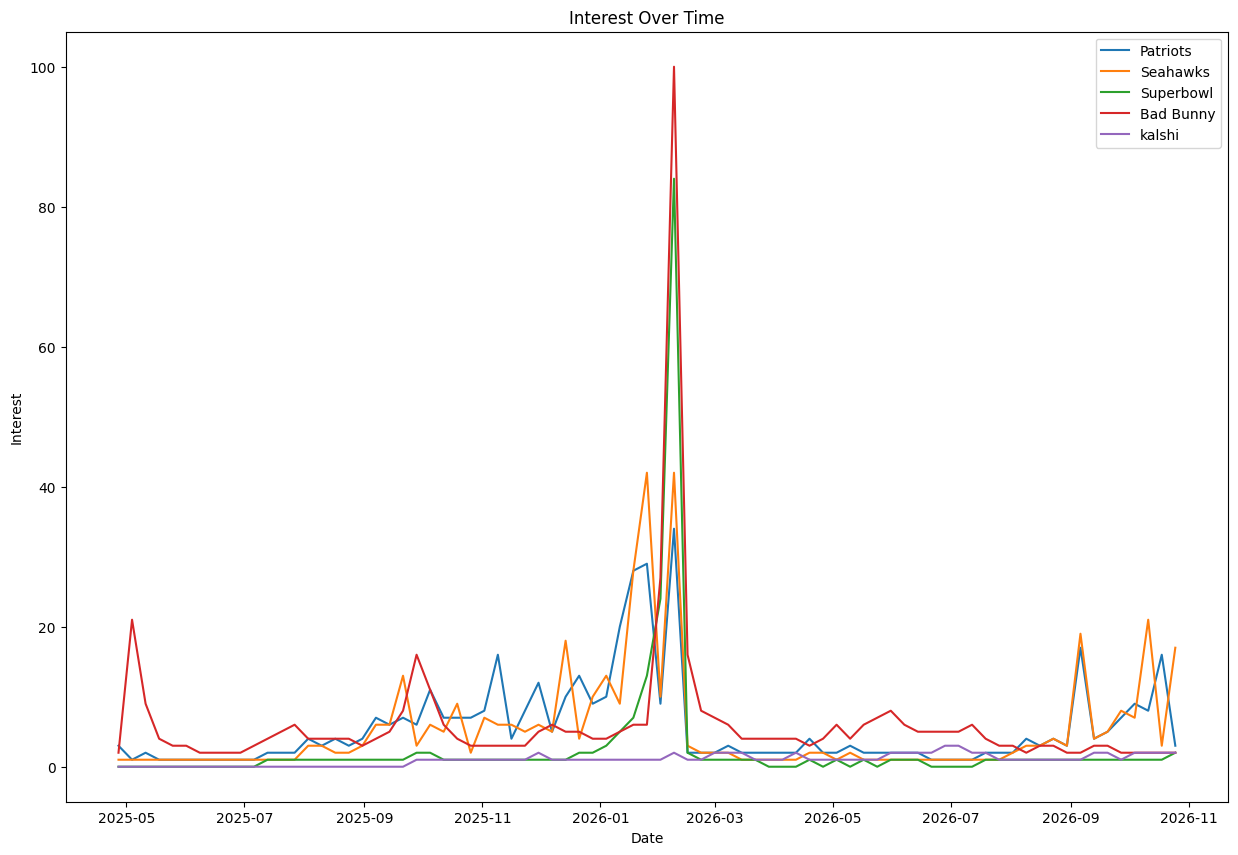

In [200]:
# Fetch the data by calling the method with parentheses
plt.figure(figsize=(15, 10))
for kw in kw_list:
  plt.plot(data.index, data[kw], label=kw)
  plt.title('Interest Over Time')
  plt.xlabel('Date')
  plt.ylabel('Interest')
plt.legend()
plt.show()

The above visual graphs the Google search popularity of the terms "Patriots", "Seahawks", "Superbowl", "Bad Bunny", which are all relevant to the 2026 Superbowl.

I also searched the term Kalshi, the popular prediction market platform, to see if there was any relation. It's clear that there was a major spike in people searching for this term.

Important things to note:
- the rise in searches for Bad Bunny occured in May 2025 due to the announcement of a world tour
- the Seahawks are slightly more popular becasue they won
- the term "Patriots" could relate to its literal use case, not just the New England Patriots, but its pattern is similar to the Seahawks

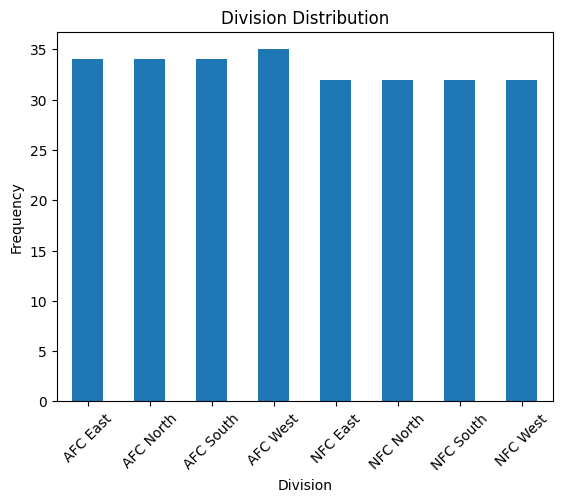

In [201]:
df['Division'].value_counts().sort_index().plot(kind='bar')

plt.title("Division Distribution")
plt.xlabel("Division")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

The NFL has 8 total divisions, split by 2 conferences, the American Football Conference (AFC) and the National Football Conference (NFC). AFC West had 35 games due to an interconference matchup for scheduling.

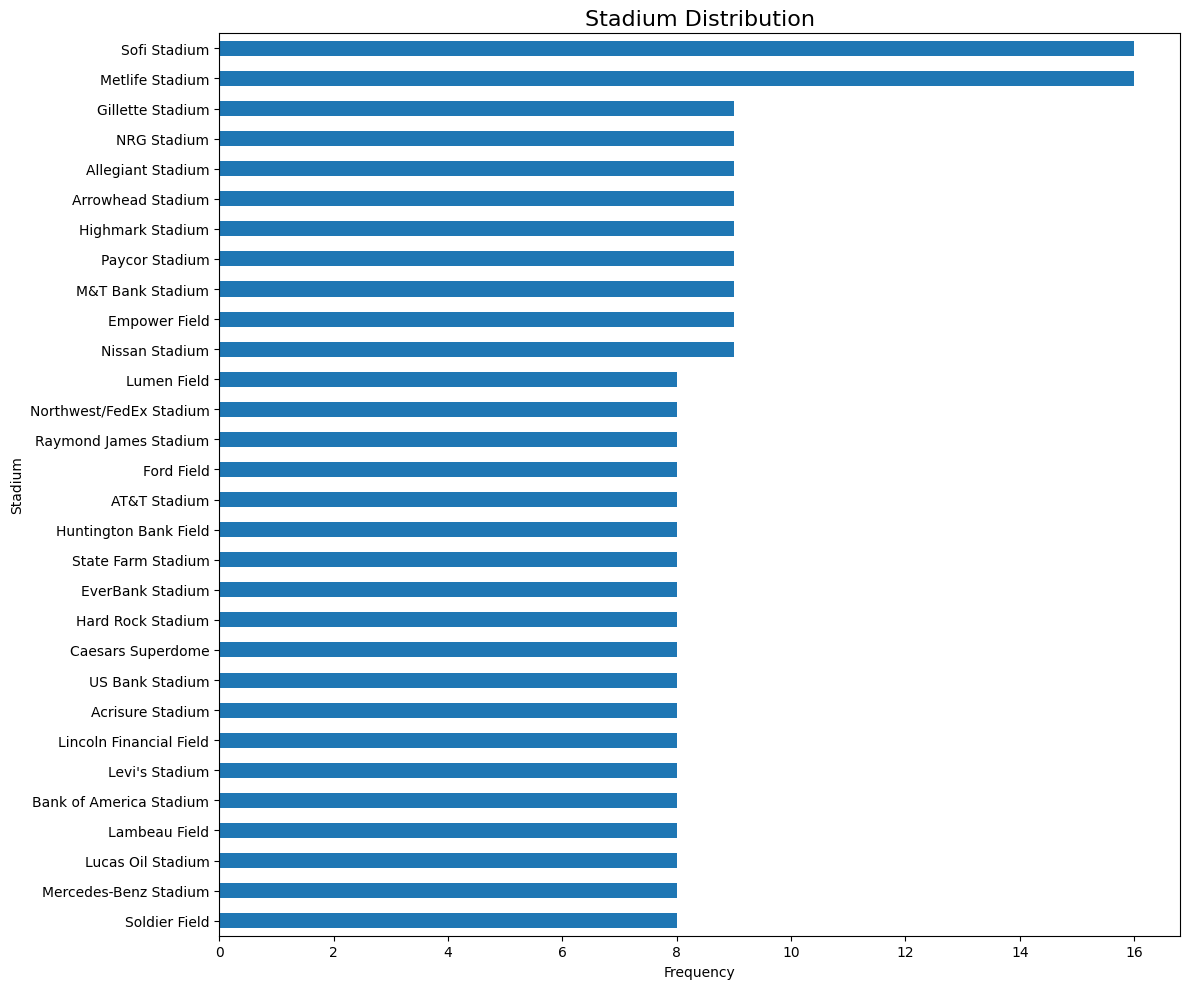

In [202]:
plt.figure(figsize=(12, 10))

df['Stadium'].value_counts().sort_values().plot(kind='barh')

plt.title("Stadium Distribution", fontsize=16)
plt.xlabel("Frequency")
plt.ylabel("Stadium")

plt.tight_layout()
plt.show()

LA Rams and Chargers both play out of Sofi Stadium and Metlife Stadium has both the Mets and Giants, which could help explian why they host twice the games of most other stadiums.

Because the NFL expanded to a 17-game schedule, some stadiums hosted 9 games instead of the standard 8, throughout the season.

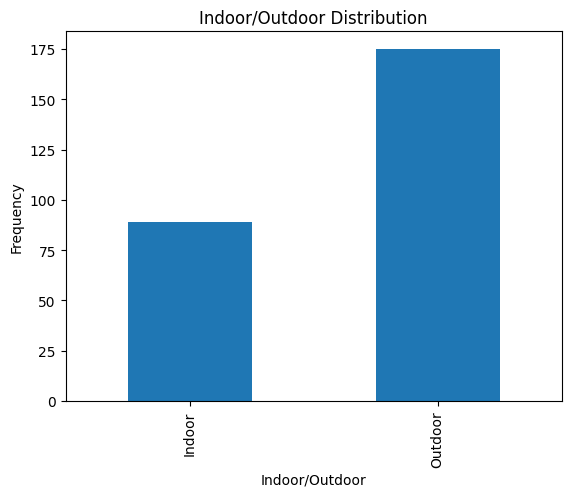

In [203]:
df['Indoor/Outdoor'].value_counts().sort_index().plot(kind='bar')

plt.title("Indoor/Outdoor Distribution")
plt.xlabel("Indoor/Outdoor")
plt.ylabel("Frequency")
plt.show()

This chart shows that most of the stadiums and games played take place outdoors, with just about half being indoor games. This could be a potential explanatory variable in a team winning or losing, providing certain advantages.

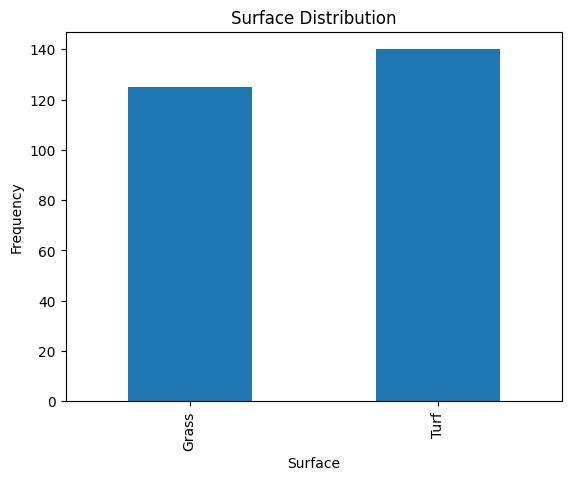

In [204]:
df['Surface'].value_counts().sort_index().plot(kind= 'bar')

plt.title("Surface Distribution")
plt.xlabel("Surface")
plt.ylabel("Frequency")
plt.show()

This bar chart shows that NFL games were played slightly more frequently on turf than on grass, indicating a relatively balanced distribution of playing surfaces.

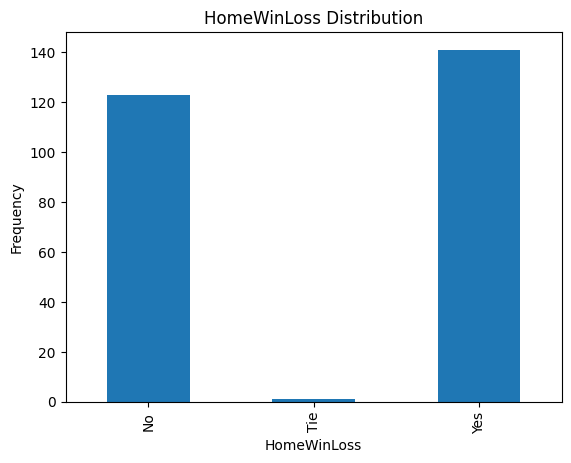

In [205]:
df['HomeWinLoss'].value_counts().sort_index().plot(kind= 'bar')

plt.title("HomeWinLoss Distribution")
plt.xlabel("HomeWinLoss")
plt.ylabel("Frequency")
plt.show()

This bar chart shows that home teams won slightly more games than they lost, with only one tie, suggesting a modest home-field advantage.

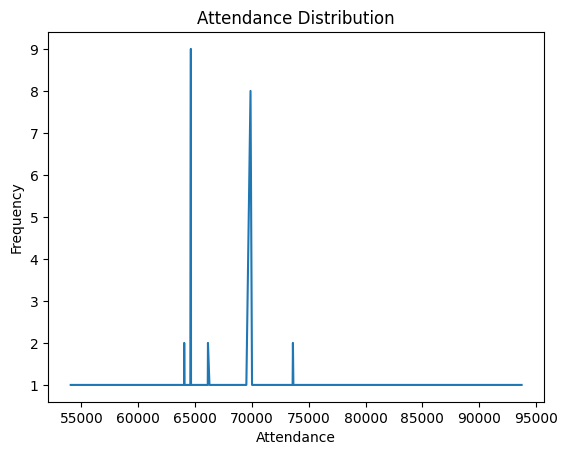

In [206]:
df['Attendance'].value_counts().sort_index().plot(kind= 'line')

plt.title("Attendance Distribution")
plt.xlabel("Attendance")
plt.ylabel("Frequency")
plt.show()

Attendance varies across NFL games, with most attendance values occurring only once and a few concentrated around 65,000–70,000 spectators.

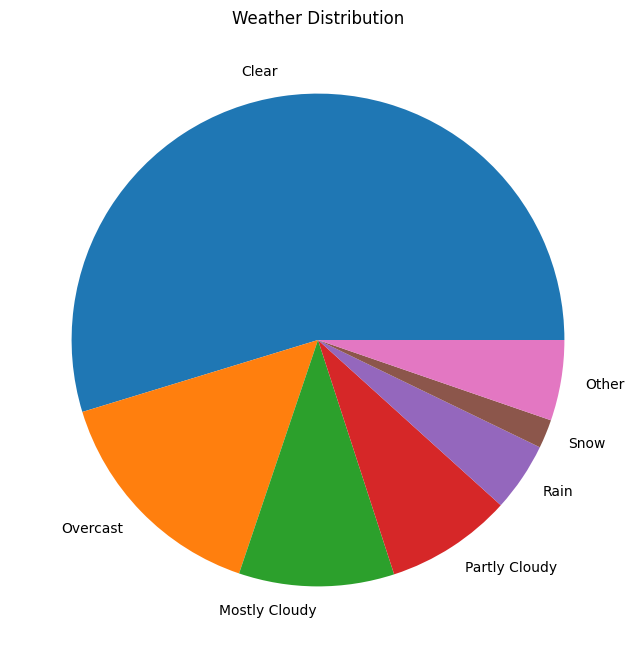

In [207]:
weather_counts = df['Weather'].value_counts()

top_weather = weather_counts.head(6)
other = weather_counts.iloc[6:].sum()

weather_plot = pd.concat([
    top_weather,
    pd.Series({'Other': other})])

plt.figure(figsize=(10, 8))

weather_plot.plot(
    kind='pie')

plt.title("Weather Distribution")
plt.ylabel("")
plt.show()

Clear weather accounts for the majority of NFL games, followed by overcast and mostly cloudy conditions, while rain and snow occur less frequently.

## Correlation across variables

In [208]:
df['Win'] = df['HomeWinLoss'].map({'Yes': 1, 'No': 0})

df['Attendance'].corr(df['Win'])

np.float64(0.06729868250707456)

In [209]:
df['Win'].value_counts(dropna=False)

,count
Win,
1.0,141
0.0,123
NaN,1


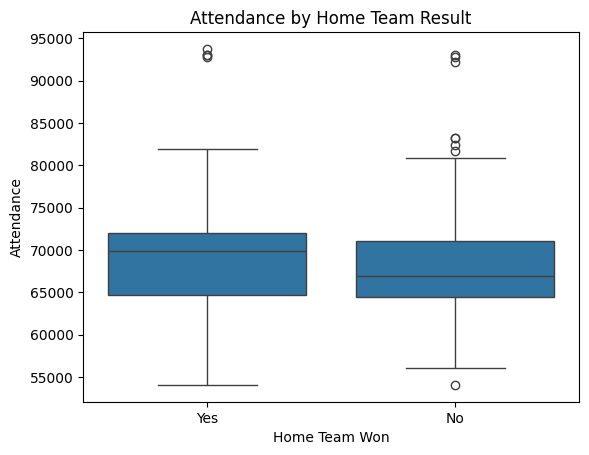

In [210]:
sns.boxplot(
    data=df[df['HomeWinLoss'] != 'Tie'],
    x='HomeWinLoss',
    y='Attendance',
    order=['Yes', 'No'])

plt.title("Attendance by Home Team Result")
plt.xlabel("Home Team Won")
plt.ylabel("Attendance")
plt.show()

One tie game was removed for clarity of visualization.

These boxplots show the relationship between attendance and whether or not the team had a win at home. The results show that there is not a clear establishment that larger crowds lead to better performance.

In [211]:
df['Indoor'] = df['Indoor/Outdoor'].map({'Indoor': 1, 'Outdoor': 0})

df['Win'] = df['HomeWinLoss'].map({'Yes': 1, 'No': 0})

In [212]:
df['Indoor'].corr(df['Win'])
df.groupby('Indoor/Outdoor')['Win'].mean() * 100

,Win
Indoor/Outdoor,
Indoor,52.272727
Outdoor,54.285714


Home teams playing in outdoor stadiums had a slightly higher win rate (54.29%) than those playing indoors (52.27%), indicating a minimal difference of approximately 2 percentage points and suggesting that stadium type has little association with home-team victories.

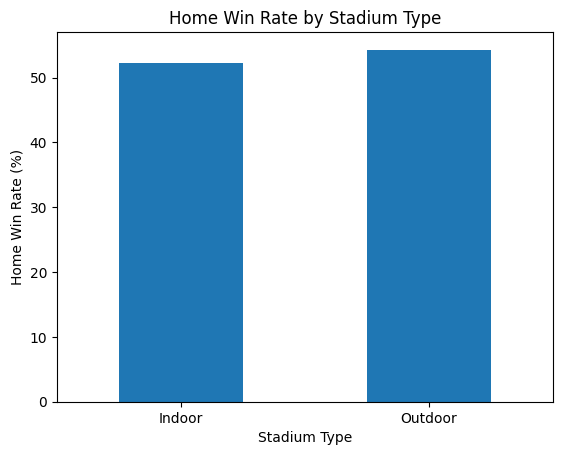

In [213]:
(df.groupby('Indoor/Outdoor')['Win'].mean() * 100).plot(kind='bar')

plt.title("Home Win Rate by Stadium Type")
plt.xlabel("Stadium Type")
plt.ylabel("Home Win Rate (%)")
plt.xticks(rotation=0)
plt.show()

Home teams playing in outdoor stadiums had a slightly higher win rate (approximately 54%) than those playing indoors (52%). However, the small difference suggests that stadium type alone may not be a meaningful predictor of game outcomes.

In [214]:
df['Win'] = df['HomeWinLoss'].map({'Yes': 1, 'No': 0})

df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')

df['Temperature'].corr(df['Win'])

np.float64(0.06644100902407032)

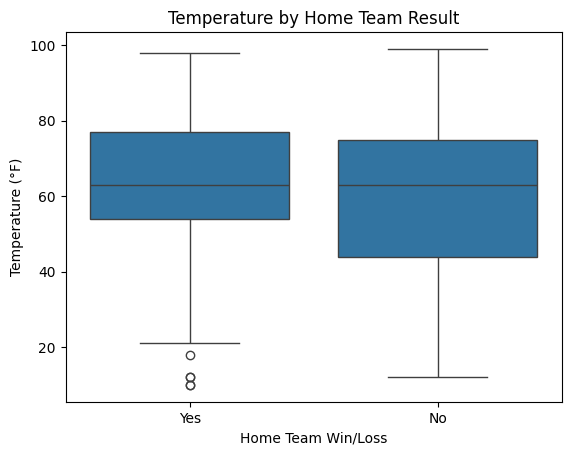

In [215]:
sns.boxplot(
    data=df[df['HomeWinLoss'] != 'Tie'],
    x='HomeWinLoss',
    y='Temperature',
    order=['Yes', 'No'])

plt.title("Temperature by Home Team Result")
plt.xlabel("Home Team Win/Loss")
plt.ylabel("Temperature (°F)")
plt.show()

There is a very weak relationship between temperature and home team wins based on the correlation coefficient.

One limitation is the difference between indoor games and outdoor games due to temperature or climate control.

In [216]:
df['WindSpeed'].corr(df['Temperature'])

np.float64(-0.18274927547941014)

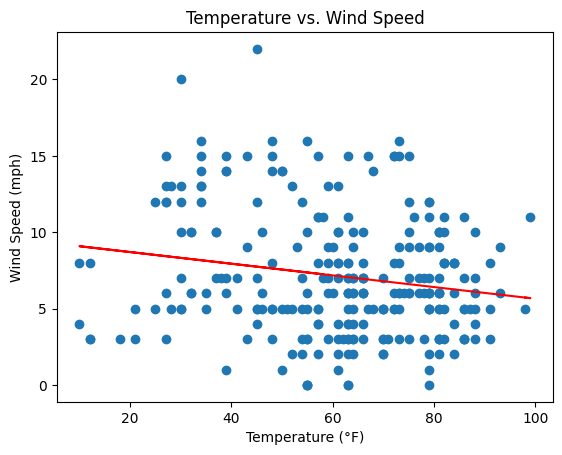

In [217]:
plt.scatter(df['Temperature'], df['WindSpeed'])
x = df['Temperature']
y = df['WindSpeed']

slope, intercept = np.polyfit(x.dropna(), y.loc[x.dropna().index], 1)

plt.plot(x, slope * x + intercept, color='red')

plt.title("Temperature vs. Wind Speed")
plt.xlabel("Temperature (°F)")
plt.ylabel("Wind Speed (mph)")
plt.show()

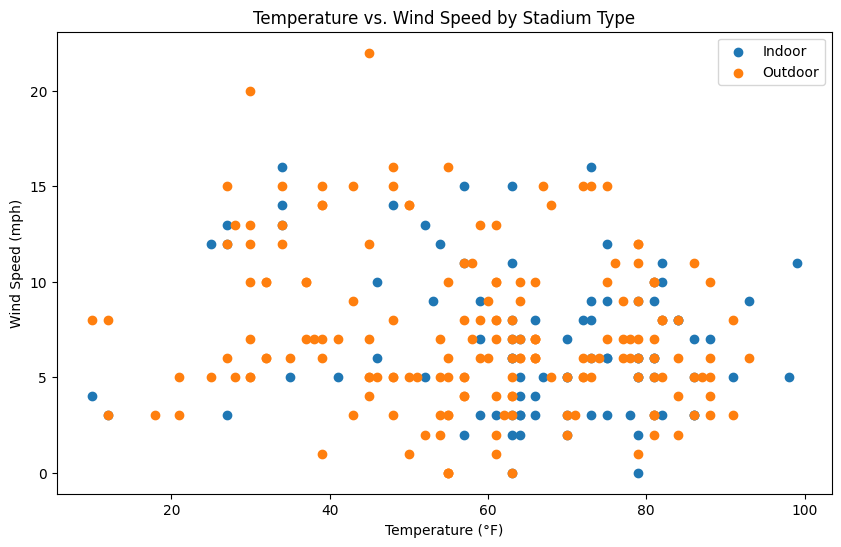

In [218]:
plt.figure(figsize=(10, 6))

for stadium_type, group in df.groupby('Indoor/Outdoor'):
    plt.scatter(
        group['Temperature'],
        group['WindSpeed'],
        label=stadium_type)

plt.title("Temperature vs. Wind Speed by Stadium Type")
plt.xlabel("Temperature (°F)")
plt.ylabel("Wind Speed (mph)")
plt.legend()
plt.show()

There is not a clear relationship between temperature and wind speed because there is variation across both indoor and outdoor stadiums.

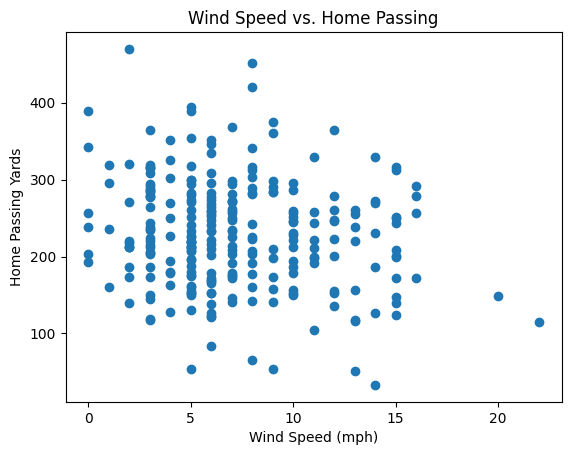

-0.1618372714766993


In [219]:
plt.scatter(df['WindSpeed'], df['HomePassing'])

plt.title("Wind Speed vs. Home Passing")
plt.xlabel("Wind Speed (mph)")
plt.ylabel("Home Passing Yards")
plt.show()

print(df['WindSpeed'].corr(df['HomePassing']))

There is a weak negative correlation (r = -0.162) between wind speed and home-team passing yards, suggesting that higher wind speeds are generally associated with slightly lower passing totals. This relationship is also reflected in the scatterplot above, although considerable variation remains across games.

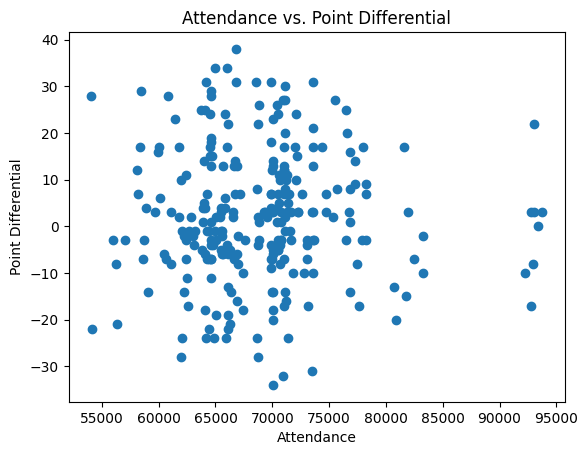

-0.009486678810757466


In [220]:
plt.scatter(df['Attendance'], df['PointDiff'])

plt.title("Attendance vs. Point Differential")
plt.xlabel("Attendance")
plt.ylabel("Point Differential")
plt.show()

print(df['Attendance'].corr(df['PointDiff']))

The correlation is nearly zero (r = -0.009), indicating virtually no linear relationship between attendance and scoring margins.

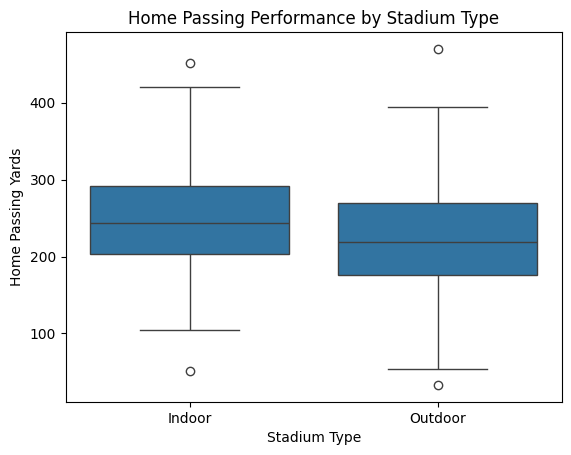

In [221]:
sns.boxplot(
    data=df,
    x='Indoor/Outdoor',
    y='HomePassing')

plt.title("Home Passing Performance by Stadium Type")
plt.xlabel("Stadium Type")
plt.ylabel("Home Passing Yards")
plt.show()

Home teams playing indoors had a higher median passing total (approximately 245 yards) than those playing outdoors (220 yards), suggesting a modest advantage in indoor passing performance.